# Polymarket EDA

## Preamble

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import sqlite3

In [2]:
con = sqlite3.connect("../polymarket-scraper/events.db")

df = pd.read_sql_query("SELECT * FROM events", con)


print("=== Closed Markets by Volume ===")

closed_markets = []

for markets_str in df['markets'].dropna():
    try:
        # Depending on how the db was read, `markets_str` might already be a list or a string
        if isinstance(markets_str, str):
            markets_list = json.loads(markets_str)
        else:
            markets_list = markets_str
            
        for m in markets_list:
            is_closed = m.get('closed', False)
            if is_closed:
                volume = float(m.get('volumeNum', 0) or 0)
                clob_token_ids_str = m.get('clobTokenIds', '[]')
                outcomes = m.get('outcomes', [])
                market_name = m.get('question', m.get('slug', 'Unknown Name')) 
                
                closed_markets.append({
                    'clob_token_ids': clob_token_ids_str,
                    'outcomes': outcomes,
                    'name': market_name,
                    'volume': volume
                })
    except Exception as e:
        # print(f"Error parsing market: {e}")
        continue

# Sort by highest volume descending
closed_markets.sort(key=lambda x: x['volume'], reverse=True)

# Print top 20
for i, market in enumerate(closed_markets[:100], 1):
    print(f"{i}. Vol: ${market['volume']:,.2f} | Name: {market['name']}")
    print(f"   ClobTokenIds: {market['clob_token_ids']}\n   Outcomes: {market['outcomes']}")

=== Closed Markets by Volume ===
1. Vol: $1,531,479,284.50 | Name: Will Donald Trump win the 2024 US Presidential Election?
   ClobTokenIds: ["21742633143463906290569050155826241533067272736897614950488156847949938836455", "48331043336612883890938759509493159234755048973500640148014422747788308965732"]
   Outcomes: ["Yes", "No"]
2. Vol: $1,037,039,118.19 | Name: Will Kamala Harris win the 2024 US Presidential Election?
   ClobTokenIds: ["69236923620077691027083946871148646972011131466059644796654161903044970987404", "87584955359245246404952128082451897287778571240979823316620093987046202296181"]
   Outcomes: ["Yes", "No"]
3. Vol: $400,409,526.89 | Name: Will Donald Trump be inaugurated?
   ClobTokenIds: ["45714870634090908403813747458214625542376052548606303175331201110938821302832", "81903344213938200361285862519406650037576398044514748634670292917494365866240"]
   Outcomes: ["Yes", "No"]
4. Vol: $378,011,506.51 | Name: Will the Sacramento Kings win the 2025 NBA Finals?
   ClobTokenId

### Run Scraper

In [3]:
import sys
import json
import ast
import pandas as pd
import sqlite3

# Add scraper directory to path so we can import from fetch_markets.py
sys.path.append("../polymarket-scraper")
from fetch_markets import get_prices_history
from requests_ratelimiter import LimiterSession

def fetch_top_events_history(markets_list, limit=100):
    session = LimiterSession(per_second=5)
    con_out = sqlite3.connect("../polymarket-scraper/price_history.db")
    
    skipped_count = 0
    valid_records = []
    
    print(f"Fetching data for top {limit} markets...\n")
    
    for idx, market in enumerate(markets_list[:limit]):
        event_name = market['name']
        
        try:
            # Parse the stringified clob token IDs list
            tokens_str = market['clob_token_ids']
            if isinstance(tokens_str, str):
                try:
                    tokens = json.loads(tokens_str)
                except:
                    tokens = ast.literal_eval(tokens_str)
            else:
                tokens = tokens_str
        except Exception:
            tokens = []
            
        outcomes = market.get('outcomes', [])
        
        if not tokens or len(tokens) == 0:
            skipped_count += 1
            continue
            
        skip_event = False
        event_data = []
        
        # Iterating through the tokens (these represent 'Yes', 'No', etc. based on index)
        for i, token_id in enumerate(tokens):
            # Try to grab the exact outcome string (e.g., 'Yes'), fallback to 'Outcome_i'
            outcome_label = outcomes[i] if i < len(outcomes) else f"Outcome_{i}"
            
            try:
                resp = get_prices_history(session, {"market": token_id, "interval": "max"})
                if resp.status_code == 200:
                    history = resp.json().get("history", [])
                    
                    if not history or len(history) == 0:
                        skip_event = True
                        break
                        
                    # Fetch all price values for this outcome
                    prices = [d['p'] for d in history]
                    
                    # If min and max price of an outcome is the same, skip the entire event
                    if min(prices) == max(prices):
                        skip_event = True
                        break
                        
                    # Tag all records with metadata
                    for rec in history:
                        rec['market_id'] = token_id
                        rec['event_name'] = event_name
                        rec['outcome'] = outcome_label
                        
                    event_data.extend(history)
                else:
                    skip_event = True
                    break
            except Exception as e:
                skip_event = True
                break
                
        # Only process if both 'Yes' and 'No' endpoints were successful and met requirements
        if skip_event or not event_data:
            print(f"[{idx+1}/{limit}] SKIPPED: {event_name}")
            skipped_count += 1
        else:
            # Event passed! All outcomes gathered properly
            print(f"[{idx+1}/{limit}] SUCCESS - Fetched {len(event_data)} historical points for: {event_name}")
            valid_records.extend(event_data)
            
    # Save the successful extractions to the DB
    if valid_records:
        df_final = pd.DataFrame(valid_records)
        df_final.to_sql("price_history_top100", con_out, if_exists="replace", index=False)
        print(f"\n-> Extracted mapping saved to new table 'price_history_top100'")
        print(f"-> Total records written: {len(df_final)}")
    else:
        print("\nNo valid records could be processed and saved.")
        
    print(f"-> Total events skipped: {skipped_count}")
    con_out.close()

# Trigger function with our pre-compiled 'closed_markets' list
fetch_top_events_history(closed_markets, limit=10000)

Fetching data for top 10000 markets...

[1/10000] SKIPPED: Will Donald Trump win the 2024 US Presidential Election?
[2/10000] SKIPPED: Will Kamala Harris win the 2024 US Presidential Election?
[3/10000] SKIPPED: Will Donald Trump be inaugurated?
[4/10000] SKIPPED: Will the Sacramento Kings win the 2025 NBA Finals?
[5/10000] SKIPPED: Will Nicolae Ciucă win the 2024 Romanian Presidential election?
[6/10000] SUCCESS - Fetched 3760 historical points for: US forces enter Iran by April 30?
[7/10000] SKIPPED: Will Zelenskyy wear a suit before July?
[8/10000] SKIPPED: Will any other Republican Politician win the 2024 US Presidential Election?
[9/10000] SKIPPED: Fed decreases interest rates by 50+ bps after January 2026 meeting?
[10/10000] SKIPPED: Fed increases interest rates by 25+ bps after January 2026 meeting?
[11/10000] SUCCESS - Fetched 3971 historical points for: US x Iran ceasefire by April 7?
[12/10000] SKIPPED: Will the Fed increase interest rates by 25+ bps after the March 2026 meet

KeyboardInterrupt: 

### Read price_history.db data

Total records: 3971
Date Range: 2026-03-24 18:10:24 to 2026-04-11 00:20:53



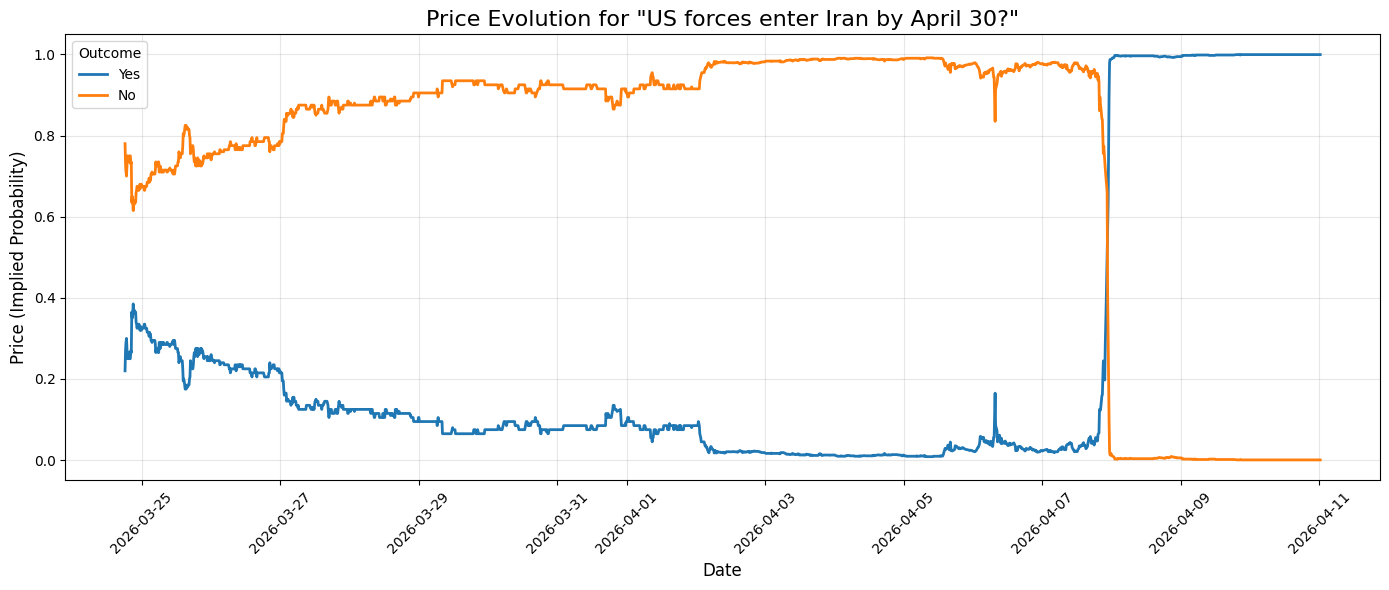

,count,mean,std,min,25%,50%,75%,max
outcome,,,,,,,,
No,1926.0,0.762882,0.329635,0.0005,0.765,0.905,0.9675,0.9915
Yes,2045.0,0.237108,0.331230,0.0085,0.035,0.095,0.2350,0.9995


In [ ]:
# import sqlite3
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns

# # Connect to the price history database
# con_ph = sqlite3.connect("../polymarket-scraper/price_history.db")
# df_ph = pd.read_sql("SELECT * FROM price_history", con_ph)

# # Convert the UNIX timestamp 't' to a readable datetime
# df_ph['datetime'] = pd.to_datetime(df_ph['t'], unit='s')

# outcome_map = {
#     "82855088893985825781350466813737280564000275725006328179621744619327480699369": "Yes",
#     "55194745453074297560900438908357749978780021444937743754846798173575377021411": "No"
# }
# df_ph['outcome'] = df_ph['market_id'].map(outcome_map).fillna(df_ph['market_id'])

# print(f"Total records: {len(df_ph)}")
# print(f"Date Range: {df_ph['datetime'].min()} to {df_ph['datetime'].max()}\n")

# # # Plot the price evolution for both market tokens
# # plt.figure(figsize=(14, 6))
# # sns.lineplot(data=df_ph, x='datetime', y='p', hue='outcome', linewidth=2)
# # plt.title('Price Evolution for "US forces enter Iran by April 30?"', fontsize=16)
# # plt.xlabel('Date', fontsize=12)
# # plt.ylabel('Price (Implied Probability)', fontsize=12)
# # plt.legend(title='Outcome')
# # plt.grid(alpha=0.3)
# # plt.xticks(rotation=45)
# # plt.tight_layout()
# # plt.show()

# # Display summary statistics
# display(df_ph.groupby('outcome')['p'].describe())

In [ ]:
# df_ph['datetime']

0      2026-03-24 18:10:24
1      2026-03-24 18:20:26
2      2026-03-24 18:30:26
3      2026-03-24 18:40:27
4      2026-03-24 18:50:28
               ...        
3966   2026-04-10 23:30:23
3967   2026-04-10 23:40:24
3968   2026-04-10 23:50:58
3969   2026-04-11 00:10:54
3970   2026-04-11 00:20:53
Name: datetime, Length: 3971, dtype: datetime64[s]

In [ ]:
import sqlite3
import pandas as pd

# Connect to the price history database
con_ph_top = sqlite3.connect("../polymarket-scraper/price_history.db")

try:
    # Query distinct event names from the newly created table
    query = "SELECT DISTINCT event_name FROM price_history_top100"
    df_events = pd.read_sql(query, con_ph_top)
    
    print(f"Total unique events to categorize: {len(df_events)}\n")
    print("=== Event Names ===")
    for idx, event_name in enumerate(df_events['event_name'].tolist(), 1):
        print(f"{idx}. {event_name}")
except Exception as e:
    print(f"Error reading from database: {e}")
finally:
    con_ph_top.close()


Total unique events to categorize: 70

=== Event Names ===
1. US forces enter Iran by April 30?
2. US x Iran ceasefire by April 7?
3. Netanyahu out by March 31?
4. Will Chelsea win the 2025–26 English Premier League?
5. US forces enter Iran by March 31?
6. Will the Iranian regime fall by March 31?
7. US x Iran ceasefire by March 31?
8. Will the Charlotte Hornets win the 2026 NBA Finals?
9. Will Atletico Madrid win the 2025–26 La Liga?
10. Military action against Iran ends by April 17, 2026?
11. Will the Chicago Bulls win the 2026 NBA Finals?
12. US x Iran ceasefire by April 15?
13. Will Bitcoin reach $150,000 in March?
14. US forces enter Iran by December 31?
15. US x Iran ceasefire by April 30?
16. Will Crude Oil (CL) hit (HIGH) $100 by end of March?
17. Will Movement for a Better Hungary (Jobbik) win the most seats in the next Hungarian parliamentary election?
18. Will Phạm Minh Chính be the next President of Vietnam?
19. Will the Golden State Warriors win the 2026 NBA Finals?
20. Wi

In [1]:
import sqlite3
import pandas as pd

# Connect to the price history database
con_ph_cats = sqlite3.connect("../polymarket-scraper/price_history.db")

try:
    # Read the manually labeled categories
    df_categories = pd.read_sql("SELECT * FROM event_categories", con_ph_cats)
    
    # Read the actual price history data
    df_prices = pd.read_sql("SELECT * FROM price_history_top100", con_ph_cats)
    
    # Merge them together on the event_name
    df_merged = df_prices.merge(df_categories, on='event_name', how='left')
    
    print(f"Total labeled events: {len(df_categories)}")
    print(f"Total price history records: {len(df_merged)}")
    
    # Display the merged dataframe containing prices, timestamps, and your custom categories!
    display(df_merged)
    
    # Optionally, look at the distribution of the labels
    if not df_categories.empty:
        print("\n=== Category Distribution ===")
        display(df_categories['category'].value_counts().to_frame())
except Exception as e:
    print(f"Error reading from database: {e}")
    print("Ensure you have run the 'label_events.py' script and labeled at least one event!")
finally:
    con_ph_cats.close()

Total labeled events: 70
Total price history records: 232253


,t,p,market_id,event_name,outcome,category
0,1774114257,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,[,Politics
1,1774114846,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,[,Politics
2,1774115445,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,[,Politics
3,1774116052,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,[,Politics
4,1774116639,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,[,Politics
...,...,...,...,...,...,...
232248,1775352645,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,"""",Sports
232249,1775353240,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,"""",Sports
232250,1775353839,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,"""",Sports
232251,1775355041,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,"""",Sports



=== Category Distribution ===


,count
category,
Sports,33
Politics,26
Finance,6
Crypto,5


In [3]:
# Fix outcome parsing artifacts
df_merged['outcome'] = df_merged['outcome'].replace({'[': 'Yes', '"': 'No'})

# Sort the values chronologically first so the arrays are in order of time
df_sorted = df_merged.sort_values(by=['event_name', 'outcome', 't'])

# Group by the event properties to aggregate timestamps and prices into lists
df_grouped = df_sorted.groupby(['event_name', 'category', 'outcome']).agg({
    't': list,
    'p': list
}).reset_index()

# Rename columns to match your exact requested format
df_grouped = df_grouped.rename(columns={
    'event_name': 'Event_name',
    't': 'timestamp',
    'p': 'price'
})

print(f"Total grouped records (Event + Outcome): {len(df_grouped)}")

# Display the grouped dataframe
display(df_grouped)

Total grouped records (Event + Outcome): 140


,Event_name,category,outcome,timestamp,price
0,Arizona Wildcats vs. Michigan Wolverines,Sports,No,"[1774820452, 1774821048, 1774822252, 177482285...","[0.5, 0.425, 0.425, 0.435, 0.515, 0.515, 0.515..."
1,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,"[1774819854, 1774820447, 1774821043, 177482224...","[0.515, 0.5, 0.575, 0.575, 0.565, 0.485, 0.485..."
2,Connecticut Huskies vs. Michigan Wolverines,Sports,No,"[1775362246, 1775362848, 1775363459, 177536405...","[0.73, 0.725, 0.725, 0.735, 0.735, 0.735, 0.73..."
3,Connecticut Huskies vs. Michigan Wolverines,Sports,Yes,"[1775362240, 1775362842, 1775363445, 177536404...","[0.27, 0.275, 0.275, 0.265, 0.265, 0.265, 0.26..."
4,Hawks vs. Knicks,Sports,No,"[1776089443, 1776090056, 1776090657, 177609124...","[0.67, 0.67, 0.595, 0.575, 0.59, 0.635, 0.635,..."
...,...,...,...,...,...
135,Will the Iranian regime fall by March 31?,Politics,Yes,"[1774114257, 1774114846, 1774115445, 177411605...","[0.0135, 0.0145, 0.0145, 0.0125, 0.0125, 0.012..."
136,Will the Los Angeles Clippers win the 2026 NBA...,Sports,No,"[1774114238, 1774114829, 1774115434, 177411602...","[0.9805, 0.9805, 0.9805, 0.9805, 0.9805, 0.980..."
137,Will the Los Angeles Clippers win the 2026 NBA...,Sports,Yes,"[1774114244, 1774114837, 1774115438, 177411603...","[0.0195, 0.0195, 0.0195, 0.0195, 0.0195, 0.019..."
138,Will the Miami Heat win the 2026 NBA Finals?,Sports,No,"[1774114238, 1774114829, 1774115434, 177411602...","[0.9885, 0.9885, 0.9885, 0.9885, 0.9885, 0.988..."


In [4]:
df_merged.to_csv("merged_price_history_data_forecasting_model.csv", index=False)
df_grouped.to_csv("grouped_price_history_data_forecasting_model.csv", index=False)